# MAIN RECON FELLGETT

Notebook implementing the reconstruction of hypercubes using raw data acquired from hadamard patterns and raw data acquired from pushbroom patterns.

Reconstructions are calculated using the pseudo inverse (in the least squares sense):
$$\bm F_\lambda = \bm H^\dagger \bm M_\lambda$$


The raw data (available for download [here](https://pilot-warehouse.creatis.insa-lyon.fr/#collection/63caa9497bef31845d991351/folder/63caaa937bef31845d991353)) must first be preprocessed by running *main_preprocess_Fellgett.py*

## Set up

In [3]:
import collections
collections.Callable = collections.abc.Callable

fig_folder = './figure/'

from pathlib import Path
from spyrit.misc.disp import add_colorbar, noaxis
import matplotlib.pyplot as plt
import numpy as np
import torch
from spyrit.core.meas  import Linear
from spyrit.core.recon import PinvNet

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# Choose to save or display
save_rec = True
save_fig = True
ext_fig = 'pdf'
dpi_fig = 600


# Data paths
data_folder = './data/2023_03_07_mRFP_DsRed_can_vs_had/' # data folder for can vs had example
mat_folder = '/Reconstruction/Mat_rc/'                   # location of prepped matrices
prep_folder = '/Preprocess/'                             # location of prepped data
hypercube_folder = 'Reconstruction/hypercube'            # where reconstructed hypercubes will be saved to 

# experimental parameters
nbin = 20*4
mudark = 105.0
sigdark = 5.0
gain = 2.6

M = 64
N = 512

# reconstruction constants
div = 1.5
alpha = 50
channel = 10, 55, 100       # to be plotted
Nl, Nh, Nc = 512, 64, 1280  # shape of preprocessed data
 
# Spectral binning **around** the central channel. The preprocessed data were binned 
# spectrally by a factor of two. Choosing c_step = 5 leads to spectral bins with 
# 2*(2*5) channels.

c_step = 10
lambda_central_list = np.arange(510, 598, 12, dtype=int)  # Central channel in nanometer
lambda_all = np.linspace(500, 608, Nc)

## Hadamard Reconstruction

Reconstruction of hypercubes from raw data acquired using Hadamard patterns

In [ ]:
Run = 'RUN0004' 

# load experimentally measured motifs
H_exp = np.load(Path(data_folder + mat_folder) / f'hadamard_matrix_{M}_{N}.npy')
H_exp /= H_exp[0,16:500].mean()
   
# Load prepedp data
filename = f'{Run}_Had_{Nl}_{Nh}_{Nc}_pos.npy'
prep_pos = np.load(Path(data_folder+prep_folder) / filename)

filename = f'{Run}_Had_{Nl}_{Nh}_{Nc}_neg.npy'
prep_neg =  np.load(Path(data_folder+prep_folder) / filename)

# spectral dimension comes first
prep_pos = np.moveaxis(prep_pos, -1, 0)
prep_neg = np.moveaxis(prep_neg, -1, 0)

# param #2
y = prep_pos - prep_neg 
y = torch.from_numpy(y)

print(f'Loaded: {filename[:-8]}')
print(f'Pos data: range={prep_pos.max() - prep_pos.min()} counts; mean={prep_pos.mean()} counts')  

y = y.to(device)
y = y.view(-1,1,N,M)

Loaded: RUN0004_Had_512_64_1280
Pos data: range=4668.0 counts; mean=263072.74484562874 counts


In [7]:
linop = Linear(torch.from_numpy(H_exp), meas_shape = (1,512), device=device) 
recon = PinvNet(linop, store_H_pinv=True, device=device)

# init output
rec = np.zeros((N, N))
recs = []
lambdas = []

for lambda_central in lambda_central_list:
    with torch.no_grad():
        c_central = np.argmin((lambda_all-lambda_central)**2) # Central channel
        m = y[c_central-c_step:c_central+c_step].sum(0, keepdim=True).to(device, torch.float32)
        print(f'reconstructing spectral bin from channels: {c_central-c_step}--{c_central+c_step}')
        rec_gpu = recon.reconstruct_pinv(m)
        rec = rec_gpu.cpu().detach().numpy().squeeze()
        rec = np.moveaxis(rec, 0, -1) # spectral channel is now the last axis
        rec = np.flip(rec,0)
        rec = np.fliplr(rec)
        rec = np.rot90(rec,-1)
                
    recs.append(rec)
    lambdas.append(lambda_central)
        
    if save_rec:
        Path(data_folder+hypercube_folder).mkdir(parents=True, exist_ok=True)
            
        save_filename = f'had_{lambda_central}_{N}x{N}.npy'
        np.save(Path(data_folder+hypercube_folder) / save_filename, rec)

        # Plot 
    fig, axs = plt.subplots(1, 1, figsize=(5,5))
    im = axs.imshow(rec) 
    axs.set_title(f'{lambda_central} nm') 
    add_colorbar(im, 'bottom') 
    noaxis(axs)

    if save_fig:
        save_filename = f'had_{lambda_central}_{N}x{N}.{ext_fig}'
        plt.savefig(Path(data_folder+hypercube_folder)/save_filename, bbox_inches='tight', dpi=dpi_fig)
    plt.close(fig)

reconstructing spectral bin from channels: 108--128
reconstructing spectral bin from channels: 251--271
reconstructing spectral bin from channels: 393--413
reconstructing spectral bin from channels: 535--555
reconstructing spectral bin from channels: 677--697
reconstructing spectral bin from channels: 819--839
reconstructing spectral bin from channels: 961--981
reconstructing spectral bin from channels: 1103--1123


### Plot

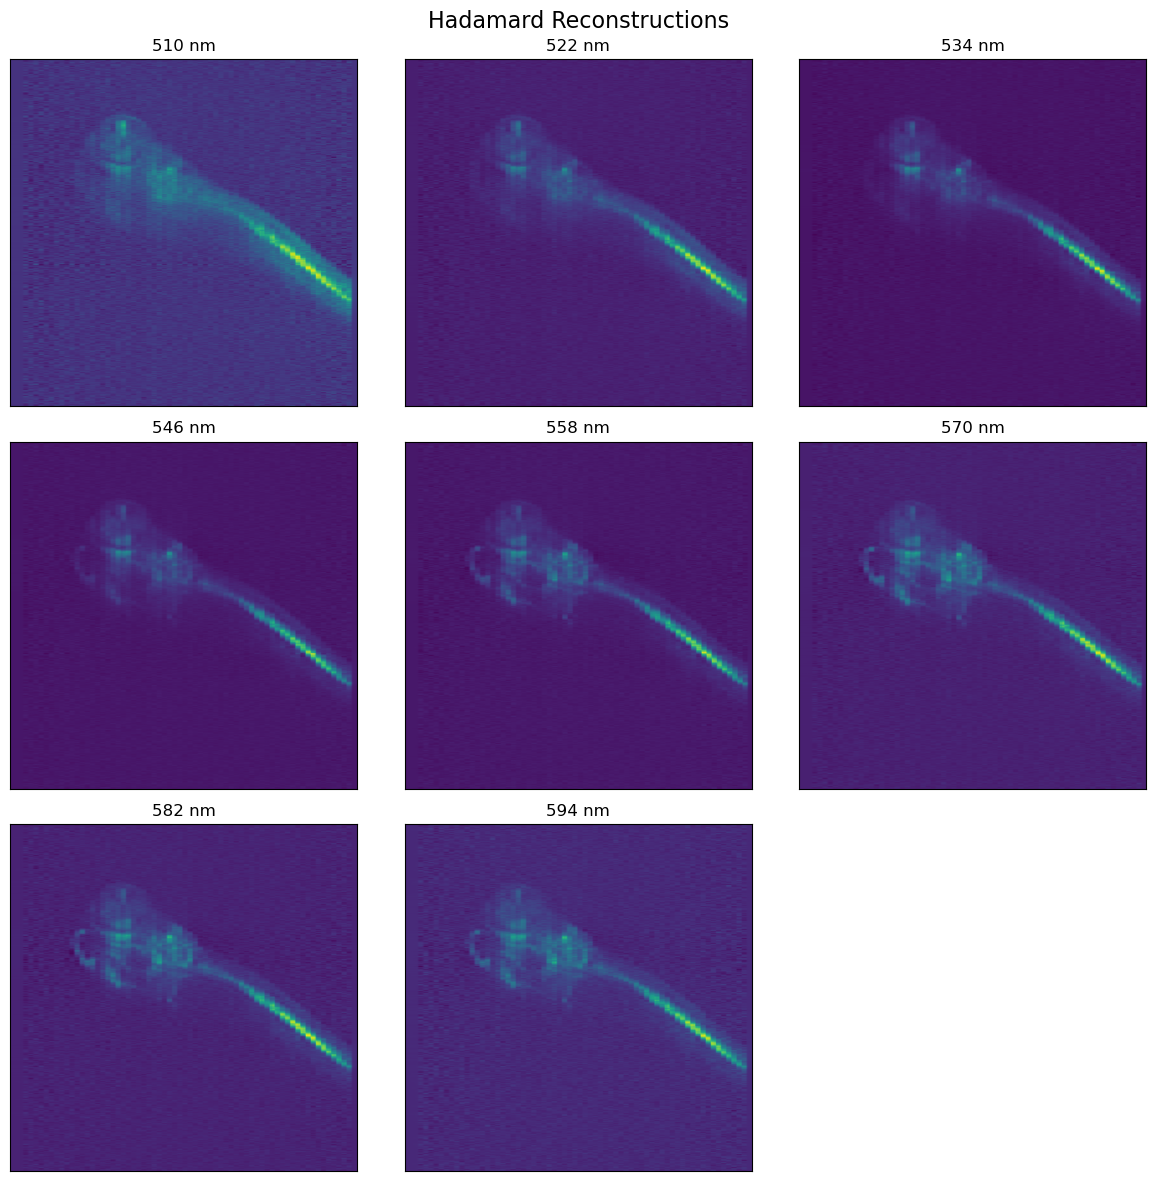

<Figure size 640x480 with 0 Axes>

In [8]:
n = len(recs)
cols = int(np.ceil(np.sqrt(n)))
rows = int(np.ceil(n / cols))

fig, axs = plt.subplots(rows, cols, figsize=(4*cols, 4*rows))
axs = np.array(axs).reshape(-1)  # flatten in case of 2D grid

for i, (rec, lam) in enumerate(zip(recs, lambdas)):
    im = axs[i].imshow(rec)
    axs[i].set_title(f"{lam} nm")
    noaxis(axs[i])

# Hide unused subplots
for j in range(i+1, len(axs)):
    axs[j].axis("off")

fig.suptitle("Hadamard Reconstructions", fontsize=16)

plt.tight_layout()
plt.show()

        
if save_fig:
    save_filename = f'hadamard_rec_all.{ext_fig}'
    plt.savefig(Path(data_folder+hypercube_folder)/save_filename, bbox_inches='tight', dpi=dpi_fig)

## Pushbroom 

Reconstruction of hypercubes from raw measures acquired using cananonical patterns

In [9]:
Run_can = 'RUN0006' 
Run_dark = 'RUN0003'  

# load motifs
H_exp = np.load(Path(data_folder + mat_folder) / f'canonical_diff_matrix_{M}_{N}.npy')

# Load prep data
filename = f'{Run_can}_Can_{Nl}_{Nh}_{Nc}_can.npy'
prep_can = np.load(Path(data_folder+prep_folder) / filename)

filename = f'{Run_dark}_Can_{Nl}_{Nh}_{Nc}_dark.npy'
prep_dark = np.load(Path(data_folder+prep_folder) / filename)

# The mean of the dark stack is substracted
prep_diff = prep_can - prep_dark.mean(1,keepdims=True)
prep_diff = np.moveaxis(prep_diff, -1, 0)
y = torch.from_numpy(prep_diff)

print(f'Loaded: {filename[:-8]}')
print(f'Pos data: range={prep_diff.max() - prep_diff.min()} counts; mean={prep_diff.mean()} counts')  

y = y.to(device)
y = y.view(-1,1,N,M) 

linop = Linear(torch.from_numpy(H_exp), meas_shape = (1,512), device=device)
recon = PinvNet(linop, store_H_pinv=True, device=device)

Loaded: RUN0003_Can_512_64_1280_
Pos data: range=18385.171875 counts; mean=7.906135869026184 counts


In [10]:
recs = []
lambdas = []

for lambda_central in lambda_central_list:
    
    with torch.no_grad():
        c_central = np.argmin((lambda_all-lambda_central)**2) # Central channel
        
        m = y[c_central-c_step:c_central+c_step].sum(0, keepdim=True).to(device, torch.float32)
        print(f'reconstructing spectral bin from channels: {c_central-c_step}--{c_central+c_step}')
        rec_gpu = recon.reconstruct_pinv(m)
        rec = rec_gpu.cpu().detach().numpy().squeeze()
                    
        rec = np.moveaxis(rec, 0, -1) # spectral channel is now the last axis
        rec = np.flip(rec,0)
        rec = np.fliplr(rec)
        rec = np.rot90(rec,-1)

    recs.append(rec)
    lambdas.append(lambda_central)        
    if save_rec:
        Path(data_folder+hypercube_folder).mkdir(parents=True, exist_ok=True)
        
        save_filename = f'can_{lambda_central}_{N}x{N}.npy'
        np.save(Path(data_folder+hypercube_folder) / save_filename, rec)
        
    # Plot
    fig, axs = plt.subplots(1, 1, figsize=(5,5))
    im = axs.imshow(rec)
    axs.set_title(f'{lambda_central} nm')
    add_colorbar(im, 'bottom')
    noaxis(axs)
        
    if save_fig:
        save_filename = f'can_{lambda_central}_{N}x{N}.{ext_fig}'
        plt.savefig(Path(data_folder+hypercube_folder)/save_filename, bbox_inches='tight', dpi=dpi_fig)
    plt.close(fig)

reconstructing spectral bin from channels: 108--128
reconstructing spectral bin from channels: 251--271
reconstructing spectral bin from channels: 393--413
reconstructing spectral bin from channels: 535--555
reconstructing spectral bin from channels: 677--697
reconstructing spectral bin from channels: 819--839
reconstructing spectral bin from channels: 961--981
reconstructing spectral bin from channels: 1103--1123


### Plot

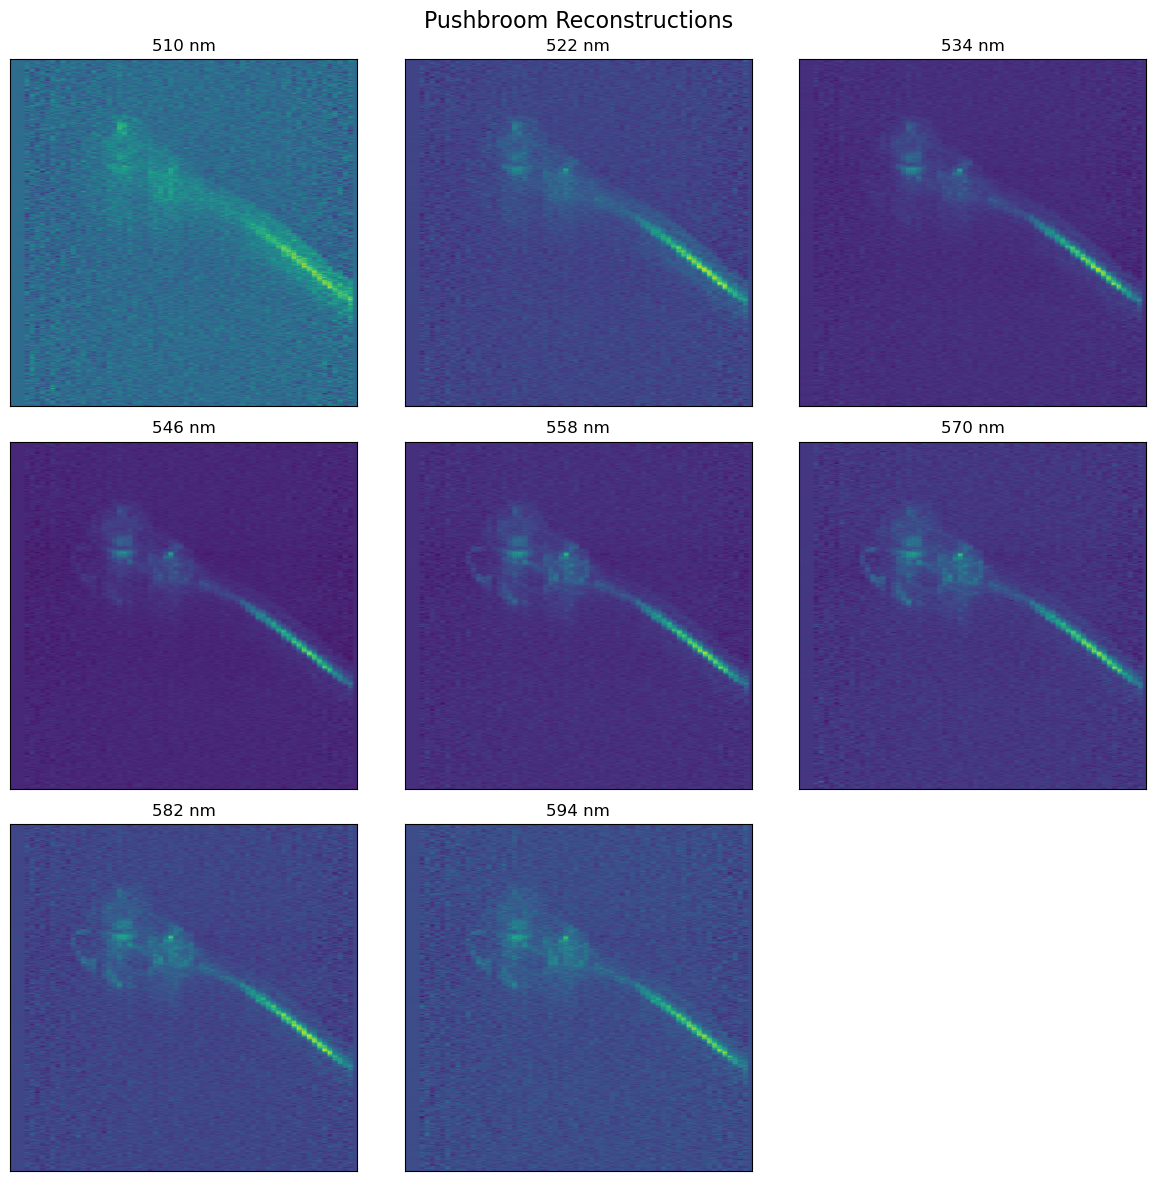

<Figure size 640x480 with 0 Axes>

In [11]:
n = len(recs)
cols = int(np.ceil(np.sqrt(n)))
rows = int(np.ceil(n / cols))

fig, axs = plt.subplots(rows, cols, figsize=(4*cols, 4*rows))
axs = np.array(axs).reshape(-1)  # flatten in case of 2D grid

for i, (rec, lam) in enumerate(zip(recs, lambdas)):
    im = axs[i].imshow(rec)
    axs[i].set_title(f"{lam} nm")
    noaxis(axs[i])

# Hide unused subplots
for j in range(i+1, len(axs)):
    axs[j].axis("off")

fig.suptitle("Pushbroom Reconstructions", fontsize=16)

plt.tight_layout()
plt.show()

        
if save_fig:
    save_filename = f'can_rec_all.{ext_fig}'
    plt.savefig(Path(data_folder+hypercube_folder)/save_filename, bbox_inches='tight', dpi=dpi_fig)

## VISUALISATION

### calculation of PSNR

In [13]:

def psnr(image, x, y, plot=True):
    """Calculates the Peak Signal-to-Noise Ratio (PSNR) of an image.

    Args:
        image: The input image.
        x: A tuple specifying the starting and ending row indices of the background.
        y: A tuple specifying the starting and ending column indices of the background.

    Returns:
        The calculated PSNR value.

    This function calculates the PSNR using the formula:

    PSNR = 20*log10(MAX/STD),

    where:
        MAX: The maximum pixel value in the image.
        STD: The standard deviation within the background region.

    The PSNR provides a measure of image quality, with higher values indicating better image quality.
    """
    imax = image.max()
    std = np.std(image[x[0]:x[1],y[0]:y[1]])
    out = 20*np.log10(imax/std)
    
    if plot:
        
        from matplotlib.patches import Rectangle
        fig, ax = plt.subplots()
        plt.imshow(image)
        plt.title(f'psnr: {out:.2f} dB')
        plt.colorbar()
        ax.add_patch(Rectangle((y[0], x[0]), y[1]-y[0]+1, x[1]-x[0]+1, linewidth=1, edgecolor='r', facecolor='none'))
    
    return out

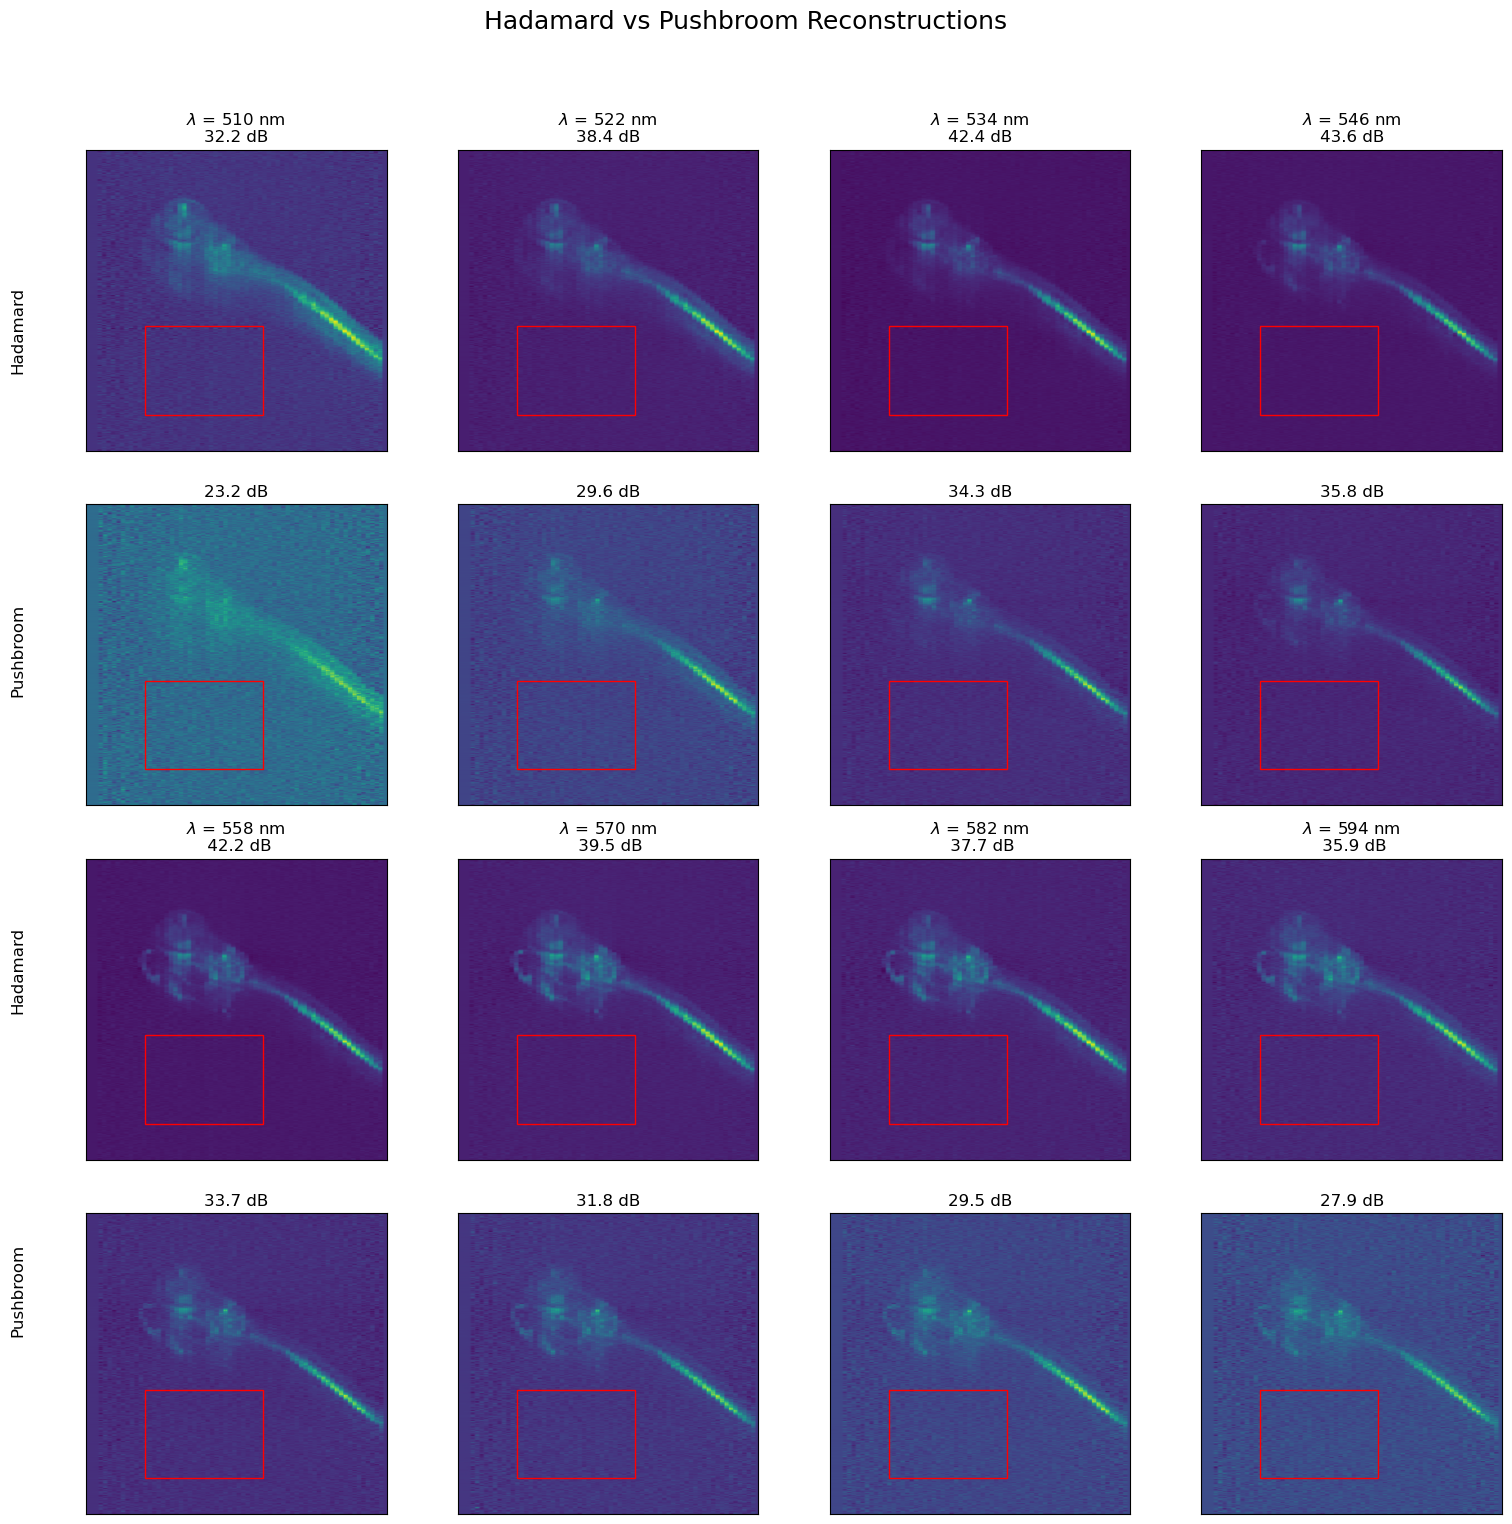

In [24]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from matplotlib.patches import Rectangle



data_folder = './data/2023_03_07_mRFP_DsRed_can_vs_had/'
save_folder = 'Reconstruction/hypercube'

lambda_central_list = np.arange(510, 598, 12, dtype=int)
N = 512

# Load data
had_recs = []
can_recs = []
x_noise = [300, 450]
y_noise = [100, 300]

psnr_had = np.zeros(len(lambda_central_list))
psnr_can = np.zeros(len(lambda_central_list))

for lambda_central in lambda_central_list:
    had = np.load(Path(data_folder+save_folder) / f'had_{lambda_central}_{N}x{N}.npy')
    can = np.load(Path(data_folder+save_folder) / f'can_{lambda_central}_{N}x{N}.npy')
    had_recs.append(had)
    can_recs.append(can)

# Compute PSNR
psnr_had = [psnr(r, x_noise, y_noise, False) for r in had_recs]
psnr_can = [psnr(r, x_noise, y_noise, False) for r in can_recs]

fig, axs = plt.subplots(4, 4, figsize=(16, 16))


for i in range(4):
    lam = lambda_central_list[i]
    
    # Hadamard
    im = axs[0, i].imshow(had_recs[i])
    axs[0, i].set_title(f"$\\lambda$ = {lam} nm\n{psnr_had[i]:.1f} dB")
    axs[0,i].add_patch(Rectangle((y_noise[0], x_noise[0]), y_noise[1]-y_noise[0]+1, x_noise[1]-x_noise[0]+1, linewidth=1, edgecolor='r', facecolor='none'))
    noaxis(axs[0, i])
    axs[0, i].set_xlabel(f"{lam} nm")  # lambda under image

    # Pushbroom
    axs[1, i].imshow(can_recs[i])
    axs[1, i].set_title(f"{psnr_can[i]:.1f} dB")
    axs[1,i].add_patch(Rectangle((y_noise[0], x_noise[0]), y_noise[1]-y_noise[0]+1, x_noise[1]-x_noise[0]+1, linewidth=1, edgecolor='r', facecolor='none'))
    noaxis(axs[1, i])

# Last 4 wavelengths
for i in range(4, 8):
    col = i - 4
    lam = lambda_central_list[i]
    
    # Hadamard
    axs[2, col].imshow(had_recs[i])
    axs[2, col].set_title(f"$\\lambda$ = {lam} nm\n {psnr_had[i]:.1f} dB")
    axs[2,col].add_patch(Rectangle((y_noise[0], x_noise[0]), y_noise[1]-y_noise[0]+1, x_noise[1]-x_noise[0]+1, linewidth=1, edgecolor='r', facecolor='none'))
    noaxis(axs[2, col])
    axs[2, col].set_xlabel(f"{lam} nm")

    # Pushbroom
    axs[3, col].imshow(can_recs[i])
    axs[3, col].set_title(f"{psnr_can[i]:.1f} dB")
    axs[3,col].add_patch(Rectangle((y_noise[0], x_noise[0]), y_noise[1]-y_noise[0]+1, x_noise[1]-x_noise[0]+1, linewidth=1, edgecolor='r', facecolor='none'))
    noaxis(axs[3, col])

# Row labels 
fig.text(0.04, 0.78, "Hadamard", va='center', rotation='vertical', fontsize=12)
fig.text(0.04, 0.58, "Pushbroom", va='center', rotation='vertical', fontsize=12)
fig.text(0.04, 0.38, "Hadamard", va='center', rotation='vertical', fontsize=12)
fig.text(0.04, 0.18, "Pushbroom", va='center', rotation='vertical', fontsize=12)


fig.suptitle("Hadamard vs Pushbroom Reconstructions", fontsize=18)


plt.tight_layout(rect=[0.06, 0.03, 1, 0.95])

# Save
save_path = Path(data_folder+save_folder) / f'comparison_grid_{N}x{N}.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')

plt.show()
